In [2]:
import os
import shutil


source = "../dataset/raw/Organic"

destination = "../dataset/organic_dataset"


os.makedirs(
    destination,
    exist_ok=True
)


for category in os.listdir(source):

    category_path = os.path.join(
        source,
        category
    )


    if os.path.isdir(category_path):

        destination_path = os.path.join(
            destination,
            category
        )


        os.makedirs(
            destination_path,
            exist_ok=True
        )


        for image in os.listdir(category_path):

            shutil.copy(

                os.path.join(
                    category_path,
                    image
                ),

                os.path.join(
                    destination_path,
                    image
                )
            )


print("Organic dataset created")

Organic dataset created


In [3]:
organic_path = "../dataset/organic_dataset"


print(
    os.listdir(organic_path)
)

['coffee_tea_bags', 'egg_shells', 'food_scraps', 'kitchen_waste', 'yard_trimmings']


In [4]:
for folder in os.listdir(organic_path):

    path = os.path.join(
        organic_path,
        folder
    )

    print(
        folder,
        len(os.listdir(path))
    )

coffee_tea_bags 157
egg_shells 125
food_scraps 147
kitchen_waste 117
yard_trimmings 131


In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2,

    rotation_range=20,

    zoom_range=0.2,

    width_shift_range=0.15,

    height_shift_range=0.15,

    horizontal_flip=True,

    brightness_range=[0.8,1.2]

)


val_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2

)

In [6]:
IMG_SIZE=(224,224)

BATCH_SIZE=32


train_data = train_datagen.flow_from_directory(

    organic_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="training"

)


val_data = val_datagen.flow_from_directory(

    organic_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="validation",

    shuffle=False

)

Found 530 images belonging to 5 classes.
Found 129 images belonging to 5 classes.


In [9]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)


base_model = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)


base_model.trainable=False

In [11]:
organic_model = Sequential([

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        5,
        activation="softmax"
    )

])

In [12]:
from tensorflow.keras.optimizers import Adam


organic_model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [13]:
history = organic_model.fit(

    train_data,

    validation_data=val_data,

    epochs=20

)

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.2434 - loss: 2.0265 - val_accuracy: 0.3488 - val_loss: 1.5860
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3075 - loss: 1.7108 - val_accuracy: 0.4574 - val_loss: 1.4030
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.4208 - loss: 1.4646 - val_accuracy: 0.5426 - val_loss: 1.2866
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.4491 - loss: 1.3130 - val_accuracy: 0.6202 - val_loss: 1.2024
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.5132 - loss: 1.2448 - val_accuracy: 0.6357 - val_loss: 1.1414
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.5415 - loss: 1.1895 - val_accuracy: 0.6434 - val_loss: 1.0910
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6038 - loss: 1.0363 - val_accuracy: 0.6589 - val_loss: 1.0444
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6245 - loss: 1.0078 - val_accuracy: 0.6512 - val_loss:

In [14]:
base_model = organic_model.layers[0]

base_model.trainable = True


for layer in base_model.layers[:-50]:
    layer.trainable = False


print("Fine tuning enabled")

Fine tuning enabled


In [15]:
from tensorflow.keras.optimizers import Adam


organic_model.compile(

    optimizer=Adam(
        learning_rate=0.00001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [16]:
fine_history = organic_model.fit(

    train_data,

    validation_data=val_data,

    epochs=10

)

Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.6453 - loss: 0.8897 - val_accuracy: 0.6744 - val_loss: 0.8605
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.6377 - loss: 0.8936 - val_accuracy: 0.6899 - val_loss: 0.8524
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7019 - loss: 0.8385 - val_accuracy: 0.6977 - val_loss: 0.8468
Epoch 4/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7189 - loss: 0.8007 - val_accuracy: 0.7054 - val_loss: 0.8450
Epoch 5/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7151 - loss: 0.7807 - val_accuracy: 0.7054 - val_loss: 0.8430
Epoch 6/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7340 - loss: 0.7460 - val_accuracy: 0.7132 - val_loss: 0.8389
Epoch 7/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7132 - loss: 0.8030 - val_accuracy: 0.7054 - val_loss: 0.8363
Epoch 8/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7226 - loss: 0.7679 - val_accuracy: 0.7054 - val_loss:

In [17]:
organic_model.save(
    "../models/final_organic_model.keras"
)

print("Organic model saved")

Organic model saved


5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 756ms/step


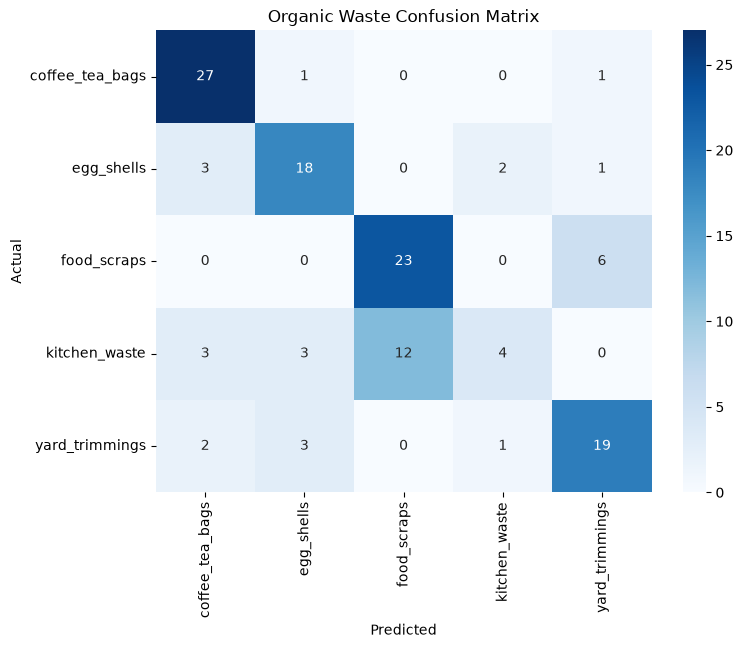

In [18]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


predictions = organic_model.predict(val_data)


y_pred = np.argmax(
    predictions,
    axis=1
)


y_true = val_data.classes


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(8,6))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(val_data.class_indices.keys()),
    yticklabels=list(val_data.class_indices.keys())
)


plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Organic Waste Confusion Matrix")

plt.show()

In [19]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(val_data.class_indices.keys())
    )
)

                 precision    recall  f1-score   support

coffee_tea_bags       0.77      0.93      0.84        29
     egg_shells       0.72      0.75      0.73        24
    food_scraps       0.66      0.79      0.72        29
  kitchen_waste       0.57      0.18      0.28        22
 yard_trimmings       0.70      0.76      0.73        25

       accuracy                           0.71       129
      macro avg       0.68      0.68      0.66       129
   weighted avg       0.69      0.71      0.68       129

